<a href="https://colab.research.google.com/github/Wasayyyyyy/CV-Tasks/blob/main/Lab12_AbdulWasay_FA23_BAI_043.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comp Vision Lab: CNN Visualization, Parameter Audit & Critical Analysis
**Student:** Abdul Wasay  |  **Roll No:** FA23-BAI-043

Run cells top to bottom (Runtime → Run all). Part I = grid, Part II = parameter audit + Keras summary.

## Part I: Filter pipeline and 5×4 grid

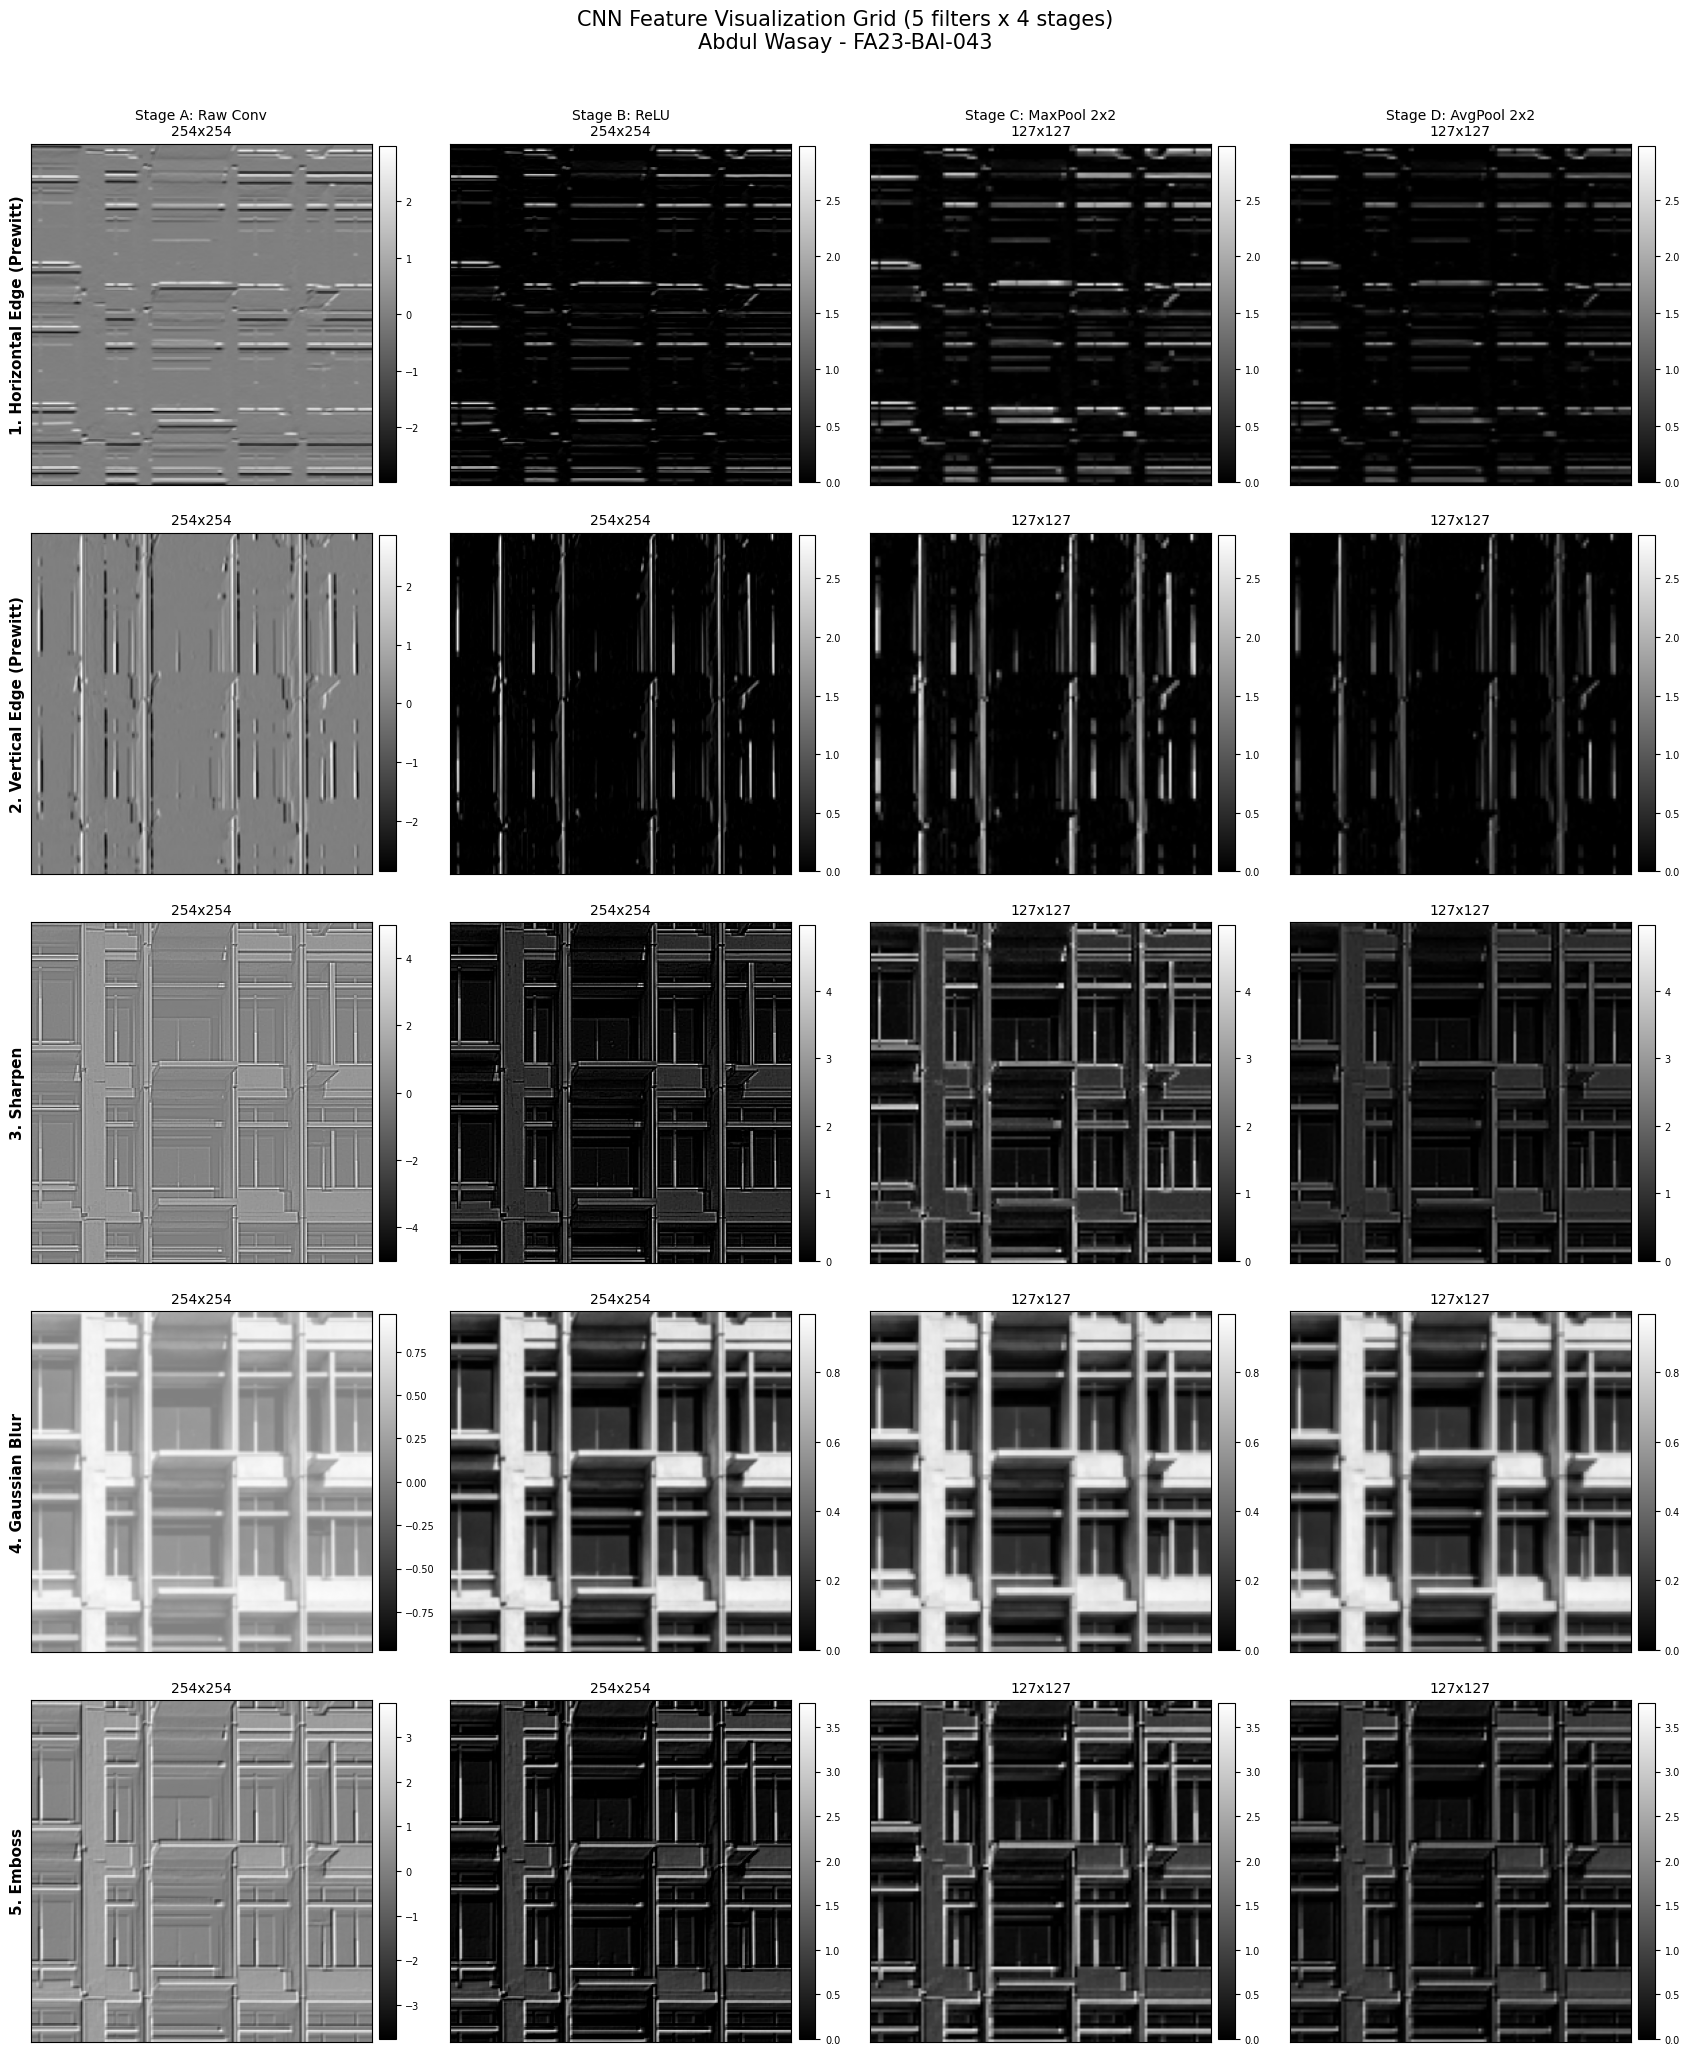

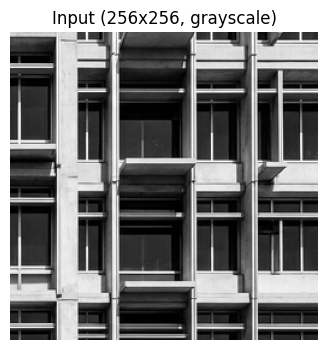

{
 "per_filter": {
  "1. Horizontal Edge (Prewitt)": {
   "A_min": -2.7568626403808594,
   "A_max": 2.976470708847046,
   "A_negative_pixels_%": 44.621489242978484,
   "B_zero_pixels_%": 47.84239568479137,
   "C_max": 2.976470708847046,
   "C_mean": 0.21064046025276184,
   "D_max": 2.069607734680176,
   "D_mean": 0.12647762894630432,
   "max_minus_avg_mean": 0.08416280895471573
  },
  "2. Vertical Edge (Prewitt)": {
   "A_min": -2.8470587730407715,
   "A_max": 2.866666793823242,
   "A_negative_pixels_%": 47.66259532519065,
   "B_zero_pixels_%": 52.035154070308145,
   "C_max": 2.866666793823242,
   "C_mean": 0.23135843873023987,
   "D_max": 2.220588207244873,
   "D_mean": 0.12963442504405975,
   "max_minus_avg_mean": 0.10172402858734131
  },
  "3. Sharpen": {
   "A_min": -3.8313727378845215,
   "A_max": 4.984313011169434,
   "A_negative_pixels_%": 26.68330336660673,
   "B_zero_pixels_%": 26.878603757207514,
   "C_max": 4.984313011169434,
   "C_mean": 0.8988627195358276,
   "D_max": 3.26

In [2]:
import base64, io, json, os

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
from PIL import Image

OUT = "."

# ------------------------------------------------------------------ input
img = np.asarray(Image.open(io.BytesIO(base64.b64decode(IMG_B64))).convert("L"), dtype=np.float32) / 255.0

# ------------------------------------------------------------------ five 3x3 kernels
KERNELS = {
    "1. Horizontal Edge (Prewitt)": np.array([[-1, -1, -1],
                                              [ 0,  0,  0],
                                              [ 1,  1,  1]], dtype=np.float32),
    "2. Vertical Edge (Prewitt)":   np.array([[-1, 0, 1],
                                              [-1, 0, 1],
                                              [-1, 0, 1]], dtype=np.float32),
    "3. Sharpen":                   np.array([[-1, -1, -1],
                                              [-1,  9, -1],
                                              [-1, -1, -1]], dtype=np.float32),
    "4. Gaussian Blur":             np.array([[1, 2, 1],
                                              [2, 4, 2],
                                              [1, 2, 1]], dtype=np.float32) / 16.0,
    "5. Emboss":                    np.array([[ 2,  1,  0],
                                              [ 1,  1, -1],
                                              [ 0, -1, -2]], dtype=np.float32),
}


# ------------------------------------------------------------------ layers
def conv2d_valid(x, k):
    """3x3 cross-correlation, stride 1, no padding (output = H-2 x W-2)."""
    win = sliding_window_view(x, k.shape)           # (H-2, W-2, 3, 3)
    return np.einsum("hwij,ij->hw", win, k)


def relu(x):
    return np.maximum(0.0, x)


def pool2x2(x, mode):
    h, w = x.shape
    blocks = x[: h // 2 * 2, : w // 2 * 2].reshape(h // 2, 2, w // 2, 2)
    return blocks.max(axis=(1, 3)) if mode == "max" else blocks.mean(axis=(1, 3))


# ------------------------------------------------------------------ run pipeline
results, stats = {}, {}
for name, k in KERNELS.items():
    A = conv2d_valid(img, k)
    B = relu(A)
    C = pool2x2(B, "max")
    D = pool2x2(B, "avg")
    results[name] = (A, B, C, D)
    stats[name] = {
        "A_min": float(A.min()), "A_max": float(A.max()),
        "A_negative_pixels_%": float((A < 0).mean() * 100),
        "B_zero_pixels_%": float((B == 0).mean() * 100),
        "C_max": float(C.max()), "C_mean": float(C.mean()),
        "D_max": float(D.max()), "D_mean": float(D.mean()),
        "max_minus_avg_mean": float((C - D).mean()),
    }

# ------------------------------------------------------------------ 5 x 4 grid
titles = ["Stage A: Raw Conv", "Stage B: ReLU", "Stage C: MaxPool 2x2", "Stage D: AvgPool 2x2"]
fig, axes = plt.subplots(5, 4, figsize=(17, 21))
for r, (name, (A, B, C, D)) in enumerate(results.items()):
    m = max(abs(A.min()), abs(A.max()))            # one scale per row -> comparable stages
    scales = [(-m, m), (0, m), (0, m), (0, m)]
    for c, (arr, (lo, hi)) in enumerate(zip((A, B, C, D), scales)):
        ax = axes[r, c]
        im = ax.imshow(arr, cmap="gray", vmin=lo, vmax=hi)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{titles[c]}\n{arr.shape[0]}x{arr.shape[1]}" if r == 0 else f"{arr.shape[0]}x{arr.shape[1]}", fontsize=10)
        if c == 0:
            ax.set_ylabel(name, fontsize=11, fontweight="bold")
        cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
        cb.ax.tick_params(labelsize=7)
fig.suptitle("CNN Feature Visualization Grid (5 filters x 4 stages)\nAbdul Wasay - FA23-BAI-043", fontsize=15)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(os.path.join(OUT, "grid_5x4.png"), dpi=130)
plt.show()

# input preview
plt.figure(figsize=(4, 4)); plt.imshow(img, cmap="gray"); plt.axis("off"); plt.title("Input (256x256, grayscale)")
plt.show()

# ------------------------------------------------------------------ Q4 demo: Conv->ReLU->Pool vs Conv->Pool->ReLU
patch = np.array([[ 4.0, -6.0],
                  [-2.0, -8.0]])                   # a 2x2 patch AFTER convolution (contains negatives)
q4 = {
    "patch": patch.tolist(),
    "relu_then_maxpool": float(relu(patch).max()),
    "maxpool_then_relu": float(relu(patch.max())),
}
patch2 = np.array([[-4.0, -6.0], [-2.0, -8.0]])    # all-negative patch
q4["all_negative_patch"] = patch2.tolist()
q4["all_negative_relu_then_maxpool"] = float(relu(patch2).max())
q4["all_negative_maxpool_then_relu"] = float(relu(patch2.max()))
q4["avgpool_example_relu_then_avg"] = float(relu(patch).mean())
q4["avgpool_example_avg_then_relu"] = float(relu(patch.mean()))

# Check commutativity on the whole real feature map, too
A = results["1. Horizontal Edge (Prewitt)"][0]
q4["full_map_max_difference"] = float(np.abs(pool2x2(relu(A), "max") - relu(pool2x2(A, "max"))).max())
q4["avgpool_full_map_max_difference"] = float(np.abs(pool2x2(relu(A), "avg") - relu(pool2x2(A, "avg"))).max())

with open(os.path.join(OUT, "stats.json"), "w") as f:
    json.dump({"per_filter": stats, "q4": q4}, f, indent=2)

print(json.dumps({"per_filter": stats, "q4": q4}, indent=1))
print("\nGrid saved as grid_5x4.png")

In [3]:
from google.colab import files
files.download('grid_5x4.png')  # optional: download the grid to print

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Part II: Manual parameter audit
Formula: (Kh × Kw × Cin + 1) × Cout. Pooling and GAP = 0 parameters.

In [4]:
def conv_params(k, cin, cout):
    return (k * k * cin + 1) * cout

def audit(name, k, pool):
    h, cin = 32, 3
    total = 0
    print(f"\n{name}  (kernel {k}x{k}, {pool} pooling)")
    for i, cout in enumerate((5, 10), start=1):
        p = conv_params(k, cin, cout)
        h = h - k + 1
        print(f"  Conv{i}: ({k}*{k}*{cin}+1)*{cout} = {k*k*cin+1}*{cout} = {p:>5}   output {h}x{h}x{cout}")
        h //= 2
        print(f"  {pool}Pool 2x2/2:                              output {h}x{h}x{cout}   params 0")
        total += p
        cin = cout
    dense = (cin + 1) * 10
    print(f"  GlobalAvgPool: output {cin}   params 0")
    print(f"  Dense: ({cin}+1)*10 = {dense}")
    total += dense
    print(f"  TOTAL = {total}")
    return total

a = audit("Model A (Standard)", 3, "Max")
b = audit("Model B (Large Kernel)", 5, "Avg")
print(f"\nIncrease A -> B: ({b}-{a})/{a} = {(b-a)/a*100:.2f}%")

# Receptive field: two stacked 3x3 layers see 5x5 (3 + 3 - 1)
print("\nOne 5x5 conv, 3->5 channels :", conv_params(5, 3, 5))
print("Two 3x3 convs, 3->5->5      :", conv_params(3, 3, 5) + conv_params(3, 5, 5))
print("One 5x5 conv, 10->10        :", conv_params(5, 10, 10))
print("Two 3x3 convs, 10->10->10   :", 2 * conv_params(3, 10, 10))


Model A (Standard)  (kernel 3x3, Max pooling)
  Conv1: (3*3*3+1)*5 = 28*5 =   140   output 30x30x5
  MaxPool 2x2/2:                              output 15x15x5   params 0
  Conv2: (3*3*5+1)*10 = 46*10 =   460   output 13x13x10
  MaxPool 2x2/2:                              output 6x6x10   params 0
  GlobalAvgPool: output 10   params 0
  Dense: (10+1)*10 = 110
  TOTAL = 710

Model B (Large Kernel)  (kernel 5x5, Avg pooling)
  Conv1: (5*5*3+1)*5 = 76*5 =   380   output 28x28x5
  AvgPool 2x2/2:                              output 14x14x5   params 0
  Conv2: (5*5*5+1)*10 = 126*10 =  1260   output 10x10x10
  AvgPool 2x2/2:                              output 5x5x10   params 0
  GlobalAvgPool: output 10   params 0
  Dense: (10+1)*10 = 110
  TOTAL = 1750

Increase A -> B: (1750-710)/710 = 146.48%

One 5x5 conv, 3->5 channels : 380
Two 3x3 convs, 3->5->5      : 370
One 5x5 conv, 10->10        : 2510
Two 3x3 convs, 10->10->10   : 1820


## Part II: Keras `model.summary()` (take the screenshot of this cell's output)

In [5]:
from tensorflow import keras
from tensorflow.keras import layers


def build(kernel, pool_layer, name):
    return keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(5, kernel, activation="relu"),
        pool_layer(pool_size=2, strides=2),
        layers.Conv2D(10, kernel, activation="relu"),
        pool_layer(pool_size=2, strides=2),
        layers.GlobalAveragePooling2D(),
        layers.Dense(10, activation="softmax"),
    ], name=name)


model_a = build(3, layers.MaxPooling2D, "Model_A_3x3_MaxPool")
model_b = build(5, layers.AveragePooling2D, "Model_B_5x5_AvgPool")
model_a.summary()   # expected total: 710
model_b.summary()   # expected total: 1,750

Model: "Model_A_3x3_MaxPool"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

Model: "Model_B_5x5_AvgPool"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 5)      │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 5)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 10, 10, 10)     │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 10)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)